# Analisis Novelty 1 vs Novelty 2 (Segmentasi Luka)
Notebook ini berisi:
1. Perbandingan angka hasil (delta absolut & relatif)
2. Analisis luka kecil & gap image-based vs data-based
3. **Template** analisis per-citra (uji statistik, bootstrap CI) -> butuh file CSV metrik per citra
4. **Template** visualisasi mask (TP/FP/FN)
5. **Template** analisis false positive
6. **Template** agregasi multi-seed

> Bagian 1-2 langsung jalan dengan angka yang sudah ada. Bagian 3-6 perlu data per-citra / prediksi dari model kamu.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.precision', 2)

image_based = pd.DataFrame({
    'Novelty1': {'Accuracy':99.80,'Specificity':99.90,'IoU':78.38,'Precision':87.56,'Recall':86.60,'Dice':85.21,'BoundaryF1':77.20},
    'Novelty2': {'Accuracy':99.81,'Specificity':99.90,'IoU':79.58,'Precision':88.63,'Recall':87.74,'Dice':86.46,'BoundaryF1':79.48}})
data_based = pd.DataFrame({
    'Novelty1': {'Accuracy':99.80,'Specificity':99.90,'IoU':85.15,'Precision':91.82,'Recall':92.13,'Dice':91.98},
    'Novelty2': {'Accuracy':99.81,'Specificity':99.90,'IoU':85.32,'Precision':91.97,'Recall':92.19,'Dice':92.08}})
small = pd.DataFrame({
    'Novelty1': {'Dice (image)':82.47,'Recall (image)':85.24,'Dice (data)':86.44,'BoundaryF1':78.22},
    'Novelty2': {'Dice (image)':84.50,'Recall (image)':86.92,'Dice (data)':87.47,'BoundaryF1':81.75}})

def add_delta(df):
    d = df.copy()
    d['Delta (N2-N1)'] = d['Novelty2'] - d['Novelty1']
    d['Rel. error reduction %'] = (d['Novelty2'] - d['Novelty1']) / (100 - d['Novelty1']) * 100
    return d

for name, df in [('IMAGE-BASED', image_based), ('DATA-BASED (pooled)', data_based), ('LUKA KECIL (n=123)', small)]:
    print('==', name); display(add_delta(df))

== IMAGE-BASED


,Novelty1,Novelty2,Delta (N2-N1),Rel. error reduction %
Accuracy,99.80,99.81,0.01,5.00
Specificity,99.90,99.90,0.00,0.00
IoU,78.38,79.58,1.20,5.55
Precision,87.56,88.63,1.07,8.60
Recall,86.60,87.74,1.14,8.51
Dice,85.21,86.46,1.25,8.45
BoundaryF1,77.20,79.48,2.28,10.00


== DATA-BASED (pooled)


,Novelty1,Novelty2,Delta (N2-N1),Rel. error reduction %
Accuracy,99.80,99.81,0.01,5.00
Specificity,99.90,99.90,0.00,0.00
IoU,85.15,85.32,0.17,1.14
Precision,91.82,91.97,0.15,1.83
Recall,92.13,92.19,0.06,0.76
Dice,91.98,92.08,0.10,1.25


== LUKA KECIL (n=123)


,Novelty1,Novelty2,Delta (N2-N1),Rel. error reduction %
Dice (image),82.47,84.50,2.03,11.58
Recall (image),85.24,86.92,1.68,11.38
Dice (data),86.44,87.47,1.03,7.60
BoundaryF1,78.22,81.75,3.53,16.21


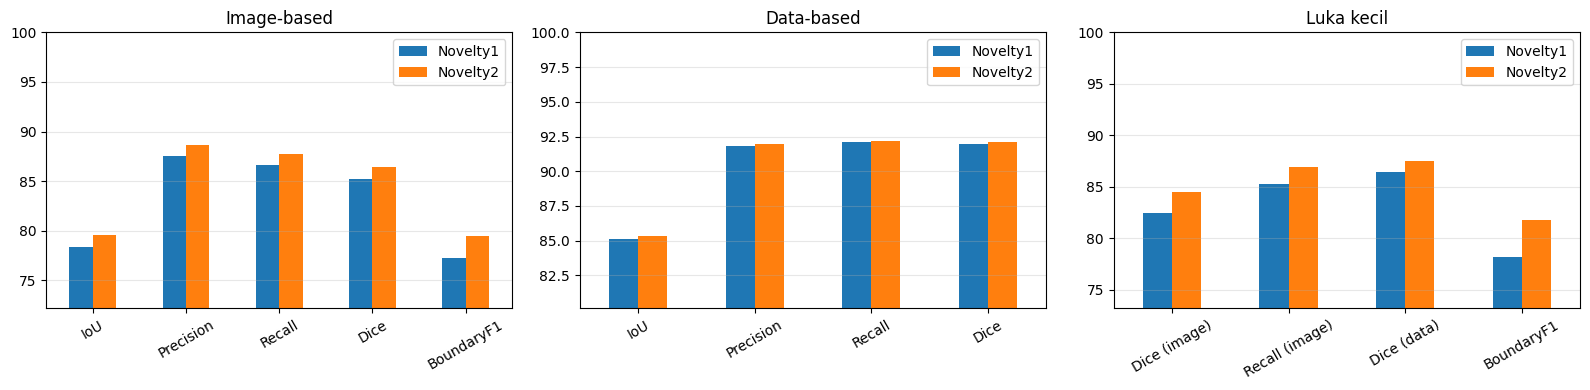

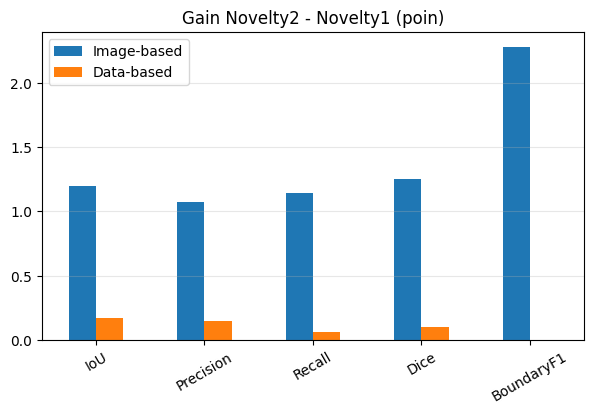

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(16,4))
for ax, (t, df) in zip(axes, [('Image-based', image_based.drop(['Accuracy','Specificity'])),
                              ('Data-based', data_based.drop(['Accuracy','Specificity'])),
                              ('Luka kecil', small)]):
    df.plot.bar(ax=ax, rot=30); ax.set_title(t); ax.set_ylim(df.values.min()-5, 100); ax.grid(axis='y', alpha=.3)
plt.tight_layout(); plt.show()

# gain per metrik (delta) - lihat di mana gain terkonsentrasi
gains = pd.concat({'Image-based': add_delta(image_based)['Delta (N2-N1)'],
                   'Data-based': add_delta(data_based)['Delta (N2-N1)']}, axis=1).drop(['Accuracy','Specificity'])
gains.plot.bar(figsize=(7,4), rot=30, title='Gain Novelty2 - Novelty1 (poin)'); plt.grid(axis='y', alpha=.3); plt.show()

In [3]:
# Gap image-based vs data-based: gap besar = citra sulit/kecil menarik rata-rata ke bawah
gap = pd.DataFrame({'N1': data_based['Dice']-image_based['Dice'].reindex(['Dice']).iloc[0] if False else None}, index=['Dice','IoU'])
gap = pd.DataFrame({
    'Novelty1': [data_based.loc['Dice','Novelty1']-image_based.loc['Dice','Novelty1'],
                 data_based.loc['IoU','Novelty1']-image_based.loc['IoU','Novelty1']],
    'Novelty2': [data_based.loc['Dice','Novelty2']-image_based.loc['Dice','Novelty2'],
                 data_based.loc['IoU','Novelty2']-image_based.loc['IoU','Novelty2']]}, index=['Dice','IoU'])
print('Gap (data-based - image-based):'); display(gap)

Gap (data-based - image-based):


,Novelty1,Novelty2
Dice,6.77,5.62
IoU,6.77,5.74


## Interpretasi dari angka yang ada

**1. Accuracy & Specificity tidak informatif.** Keduanya jenuh (~99.8-99.9) karena piksel background mendominasi. Jangan dijadikan argumen novelty; fokus ke Dice/IoU/BoundaryF1.

**2. Gain Novelty 2 terkonsentrasi di image-based & luka kecil, bukan di data-based.**
- Image-based: Dice +1.25, IoU +1.20, BoundaryF1 **+2.28**
- Data-based (pooled): Dice hanya +0.10, IoU +0.17
- Luka kecil: Dice +2.03, Recall +1.68, BoundaryF1 **+3.53**

Artinya: luka besar (yang mendominasi pooled) sudah hampir sama bagusnya di kedua model; perbaikan datang dari luka kecil dan ketepatan batas. Ini konsisten dengan hipotesis skip connection resolusi tinggi (256x256 & 128x128) menjaga detail halus.

**3. BoundaryF1 naik paling besar** -> kontur lebih presisi, sesuai klaim novelty.

**4. Gap image vs data ~6-7 poin** di kedua model -> masih ada citra sulit yang menurunkan rata-rata (cek distribusi per citra, bukan cuma mean).

**5. False positive tidak berubah (3 dari 5 citra tanpa luka) di kedua model.** Novelty 2 tidak menyentuh masalah ini. n=5 terlalu kecil untuk kesimpulan statistik, tapi ini kelemahan yang perlu dilaporkan jujur. Kandidat solusi: loss dengan penalti FP (Tversky/Focal Tversky), atau post-processing ukuran area minimum.

**6. Caveat penting:** selisih ~1-2 poin dari **satu run** belum tentu signifikan. Seed variance pada segmentasi medis sering 0.5-1.5 poin. Perlu multi-seed + uji berpasangan (bagian bawah).

## 3. Analisis per-citra (template)
Siapkan CSV per citra untuk tiap model: kolom `image_id, gt_ratio(%), dice, iou, precision, recall, bf1, fp_pixels`. Urutan `image_id` harus sama.

In [4]:
import numpy as np, pandas as pd
from scipy import stats

RES = '../output_fuseg_2021/results/'
F1 = RES + 'lg_pscse_efficientnet-b7_2026-11-06_20-24-16_per_image.csv'   # Novelty 1
F2 = RES + 'cl_dpsc_efficientnet-b7_2026-11-06_20-25-49_per_image.csv'    # Novelty 2

r1, r2 = pd.read_csv(F1), pd.read_csv(F2)
print('Kolom N1:', list(r1.columns)); print('Kolom N2:', list(r2.columns))
print(r1.head(3))

# Kandidat nama kolom -> nama standar (tambah kalau punyamu beda)
ALIASES = {
    'image_id':  ['image_id','image','img','filename','file','name','id','path'],
    'gt_ratio':  ['gt_ratio','gt_pct','gt_percent','gt_area_pct','wound_ratio','gt_area_ratio','gt_frac'],
    'dice':      ['dice','dice_score','f1'],
    'iou':       ['iou','jaccard'],
    'precision': ['precision','prec'],
    'recall':    ['recall','sensitivity','sens'],
    'bf1':       ['bf1','boundary_f1','boundaryf1','boundary_f1_score'],
    'fp_pixels': ['fp_pixels','fp','fp_px','false_positive_pixels'],
}
def standardize(df):
    low = {c.lower(): c for c in df.columns}
    ren = {}
    for std, cands in ALIASES.items():
        for c in cands:
            if c in low: ren[low[c]] = std; break
    out = df.rename(columns=ren)
    if 'image_id' in out: out['image_id'] = out['image_id'].astype(str).str.replace(r'\\.\\w+$', '', regex=True)
    return out, ren

d1, m1 = standardize(r1); d2, m2 = standardize(r2)
print('\\nMapping N1:', m1); print('Mapping N2:', m2)

need = ['image_id','dice','iou','bf1','precision','recall']
missing = [c for c in need + ['gt_ratio'] if c not in d1]
print('\\nKolom belum terdeteksi:', missing or 'tidak ada')

# Skala: kalau metrik 0-100, ubah ke 0-1 supaya seragam
for d in (d1, d2):
    for c in ['dice','iou','bf1','precision','recall']:
        if c in d and d[c].max() > 1.5: d[c] = d[c] / 100
    if 'gt_ratio' in d and d['gt_ratio'].max() <= 1.0:   # fraksi -> persen
        d['gt_ratio'] = d['gt_ratio'] * 100

d1 = d1.set_index('image_id'); d2 = d2.set_index('image_id')
common = d1.index.intersection(d2.index)
print(f'\\nCitra N1={len(d1)}, N2={len(d2)}, irisan={len(common)}')
df1, df2 = d1.loc[common], d2.loc[common]

Kolom N1: ['Name', 'GT_area_pct', 'Accuracy', 'Specificity', 'iou', 'Precision', 'Recall', 'Dice', 'BoundaryF1', 'tp', 'fp', 'fn', 'tn']
Kolom N2: ['Name', 'GT_area_pct', 'Accuracy', 'Specificity', 'iou', 'Precision', 'Recall', 'Dice', 'BoundaryF1', 'tp', 'fp', 'fn', 'tn']
   Name  GT_area_pct  Accuracy  Specificity    iou  Precision  Recall   Dice  \
0     1         0.26     99.96        99.99  86.45      94.13   91.37  92.73   
1     2         1.15     99.86        99.95  88.36      95.40   92.29  93.82   
2     3         1.90     99.84        99.92  92.14      96.05   95.76  95.91   

   BoundaryF1    tp   fp   fn      tn  
0       90.86   625   39   59  261421  
1       87.51  2778  134  232  259000  
2       82.23  4771  196  211  256966  
\nMapping N1: {'Name': 'image_id', 'GT_area_pct': 'gt_ratio', 'Dice': 'dice', 'iou': 'iou', 'Precision': 'precision', 'Recall': 'recall', 'BoundaryF1': 'bf1', 'fp': 'fp_pixels'}
Mapping N2: {'Name': 'image_id', 'GT_area_pct': 'gt_ratio', 'Dice':

## 4. Visualisasi mask: TP / FP / FN (template)
Hijau = TP, Merah = FP, Biru = FN. Fokus ke luka kecil dan citra terburuk.

Index -> img:1210 gt:1010 pred_N1:201 pred_N2:203
Contoh file prediksi N1: [PosixPath('../output_fuseg_2021/predictions/lg_pscse_efficientnet-b7_2026-11-06_20-24-16/0906.png'), PosixPath('../output_fuseg_2021/predictions/lg_pscse_efficientnet-b7_2026-11-06_20-24-16/0806.png'), PosixPath('../output_fuseg_2021/predictions/lg_pscse_efficientnet-b7_2026-11-06_20-24-16/0004.png')]
          dice_N1   dice_N2  gt_ratio
image_id                             
533          0.00  0.00e+00      0.00
580          0.00  0.00e+00      0.03
417          0.00  0.00e+00      0.00
869          0.00  0.00e+00      0.00
973          0.07  7.00e-03      0.33
349          0.20  2.12e-01      0.65
245          0.31  2.96e-01      0.03
721          0.37  4.00e-01      0.38
341          0.42  4.10e-01      0.08
412          0.47  4.56e-01      0.56


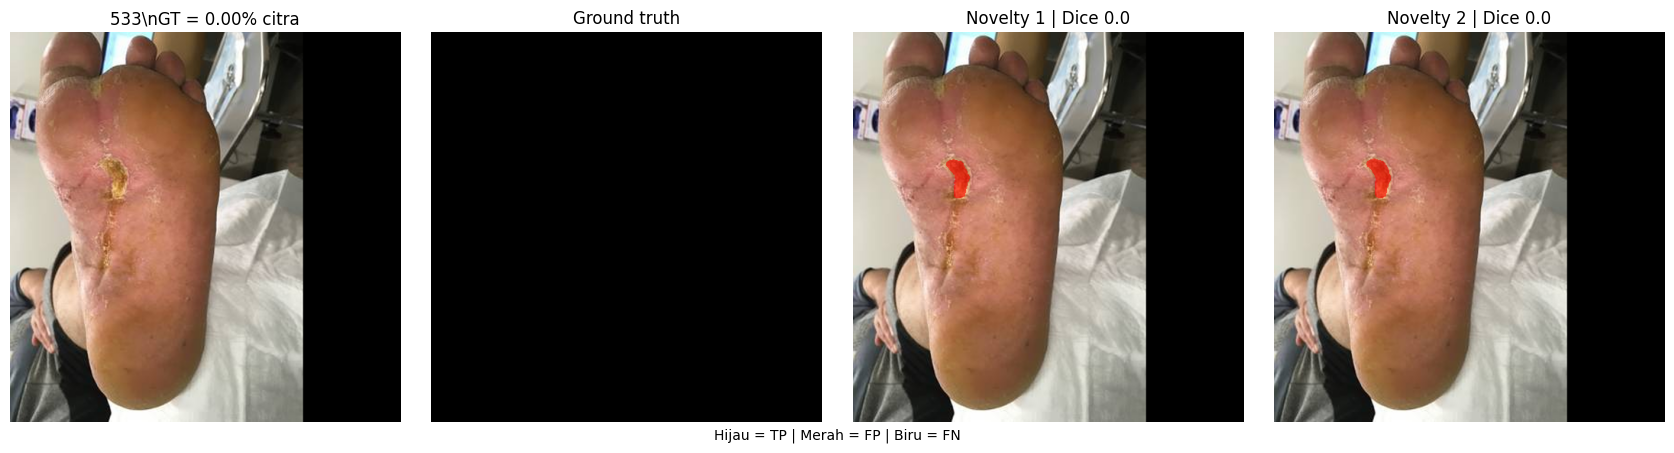

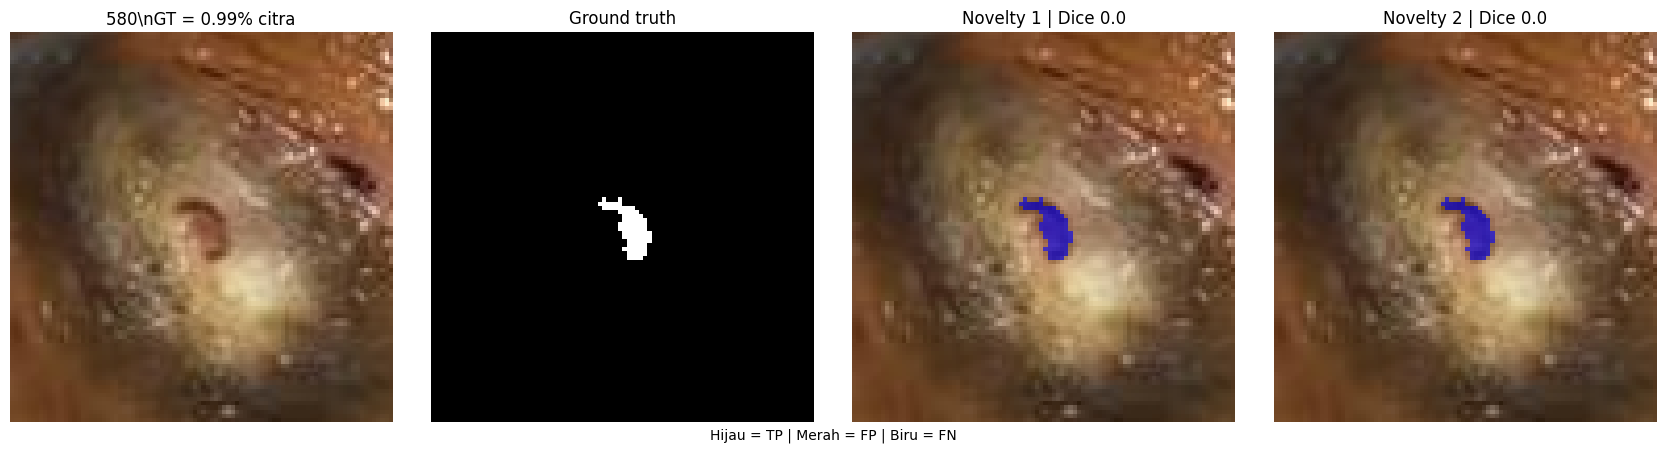

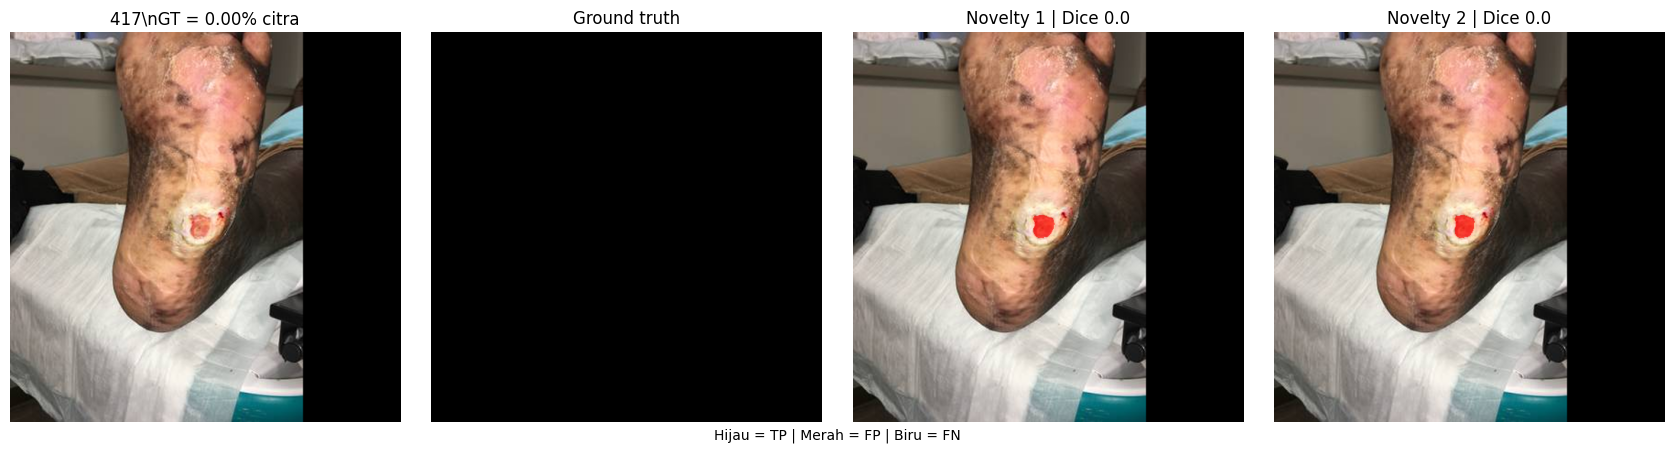

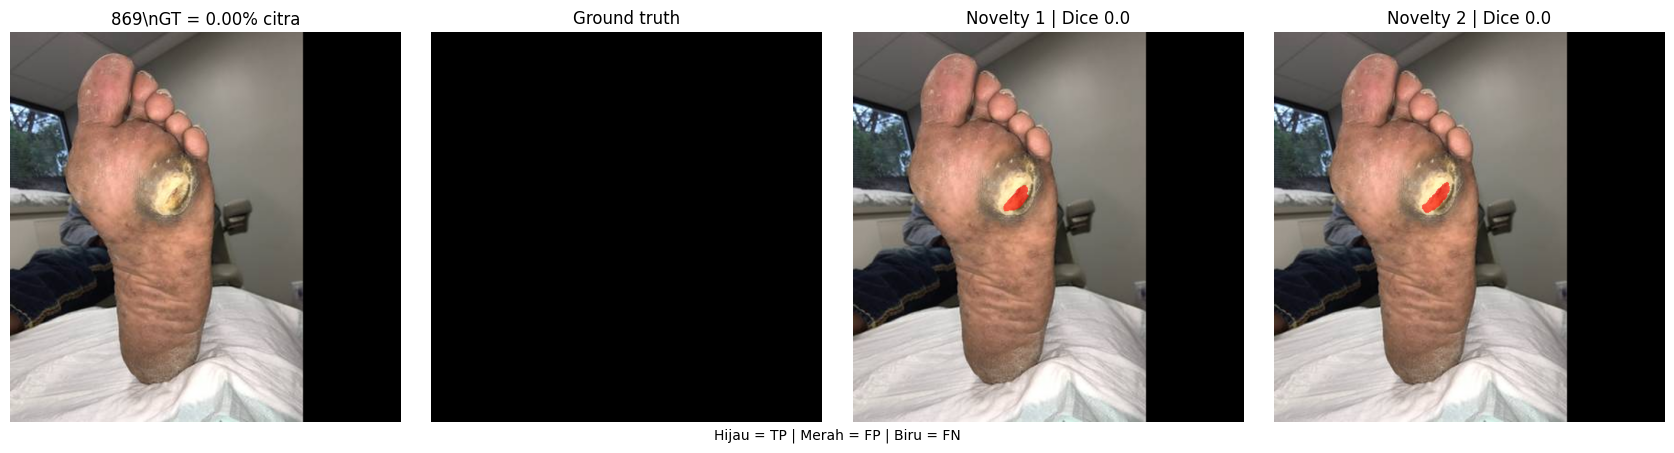

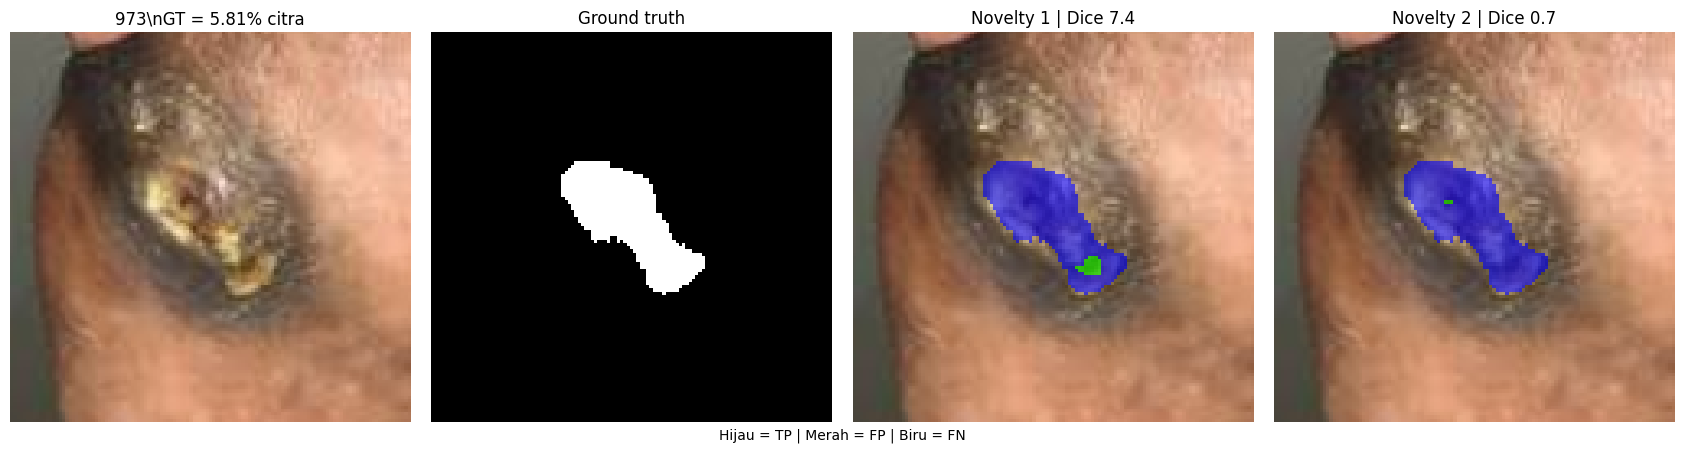

In [5]:
import cv2, numpy as np, matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path('..')                                   # notebook/ -> root proyek
RAW  = ROOT / 'data/raw/fuseg_2021'
PRED = ROOT / 'output_fuseg_2021/predictions'
PRED_N1 = PRED / 'lg_pscse_efficientnet-b7_2026-11-06_20-24-16'
PRED_N2 = PRED / 'cl_dpsc_efficientnet-b7_2026-11-06_20-25-49'

IMG_EXT = {'.png', '.jpg', '.jpeg', '.npy'}

def build_index(*dirs):
    """stem -> path, untuk semua file di dalam folder (rekursif)."""
    idx = {}
    for d in dirs:
        d = Path(d)
        if not d.exists(): continue
        for p in d.rglob('*'):
            if p.is_file() and p.suffix.lower() in IMG_EXT:
                idx.setdefault(p.stem, p)
    return idx

idx_img  = build_index(*[RAW / s / 'images' for s in ['train', 'validation', 'test']])
idx_gt   = build_index(*[RAW / s / 'labels' for s in ['train', 'validation', 'test']])
idx_p1   = build_index(PRED_N1)
idx_p2   = build_index(PRED_N2)
print(f'Index -> img:{len(idx_img)} gt:{len(idx_gt)} pred_N1:{len(idx_p1)} pred_N2:{len(idx_p2)}')
print('Contoh file prediksi N1:', list(idx_p1.values())[:3])

# Pastikan df1, df2, worst tersedia (tanpa harus menjalankan Cell 3)
if 'df1' not in globals() or 'df2' not in globals():
    raise RuntimeError('Jalankan Cell 1 dulu (load CSV per citra) -> membuat df1 & df2')

worst = (pd.DataFrame({'dice_N1': df1['dice'], 'dice_N2': df2['dice'], 'gt_ratio': df1['gt_ratio']})
           .dropna().sort_values('dice_N2').head(10))
print(worst.round(3))

def lookup(idx, iid):
    """Cocokkan stem persis; kalau tidak ada, coba yang mengandung iid (mis. suffix _pred)."""
    if iid in idx: return idx[iid]
    for k, v in idx.items():
        if iid in k or k in iid: return v
    return None

def read_array(path):
    path = Path(path)
    if path.suffix.lower() == '.npy': return np.load(path)
    return cv2.imread(str(path), cv2.IMREAD_UNCHANGED)

def read_rgb(path):
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def read_mask(path, shape_hw=None, thr=0.5):
    """Baca GT atau prediksi -> bool. Menangani 0/1, 0/255, probabilitas, dan 3-channel."""
    a = read_array(path).squeeze()
    if a.ndim == 3: a = a[..., 0] if a.shape[-1] in (1, 3, 4) else a[0]
    a = a.astype(np.float32)
    if a.max() > 1.5: a = a / 255.0
    if shape_hw is not None and a.shape != tuple(shape_hw):
        a = cv2.resize(a, (shape_hw[1], shape_hw[0]), interpolation=cv2.INTER_NEAREST)
    return a > thr

def overlay_error(img, gt, pred):
    gt, pred = gt.astype(bool), pred.astype(bool)
    out = img.astype(np.float32) / 255.0
    col = np.zeros_like(out)
    col[gt & pred] = [0, 1, 0]      # TP hijau
    col[~gt & pred] = [1, 0, 0]     # FP merah
    col[gt & ~pred] = [0, 0, 1]     # FN biru
    m = (gt | pred)[..., None]
    return np.where(m, 0.4 * out + 0.6 * col, out)

def dice_of(gt, pred, eps=1e-8):
    tp = (gt & pred).sum()
    return 2 * tp / (gt.sum() + pred.sum() + eps)

def show_case(iid, crop_to_wound=False, pad=40):
    pi, pg, p1p, p2p = (lookup(i, iid) for i in (idx_img, idx_gt, idx_p1, idx_p2))
    miss = {n: p for n, p in zip(['img', 'gt', 'pred_N1', 'pred_N2'], (pi, pg, p1p, p2p)) if p is None}
    if miss:
        print(f'[SKIP] {iid}: tidak ketemu -> {list(miss)}'); return
    img = read_rgb(pi)
    H, W = img.shape[:2]
    gt = read_mask(pg, (H, W)); p1 = read_mask(p1p, (H, W)); p2 = read_mask(p2p, (H, W))

    if crop_to_wound and gt.any():                  # zoom ke area luka (berguna untuk luka kecil)
        ys, xs = np.where(gt | p1 | p2)
        y0, y1 = max(ys.min() - pad, 0), min(ys.max() + pad, H)
        x0, x1 = max(xs.min() - pad, 0), min(xs.max() + pad, W)
        img, gt, p1, p2 = img[y0:y1, x0:x1], gt[y0:y1, x0:x1], p1[y0:y1, x0:x1], p2[y0:y1, x0:x1]

    fig, ax = plt.subplots(1, 4, figsize=(17, 4.5))
    ax[0].imshow(img); ax[0].set_title(f'{iid[:18]}\\nGT = {gt.mean()*100:.2f}% citra')
    ax[1].imshow(gt, cmap='gray'); ax[1].set_title('Ground truth')
    ax[2].imshow(overlay_error(img, gt, p1)); ax[2].set_title(f'Novelty 1 | Dice {dice_of(gt, p1)*100:.1f}')
    ax[3].imshow(overlay_error(img, gt, p2)); ax[3].set_title(f'Novelty 2 | Dice {dice_of(gt, p2)*100:.1f}')
    for a in ax: a.axis('off')
    fig.suptitle('Hijau = TP | Merah = FP | Biru = FN', y=0.02, fontsize=10)
    plt.tight_layout(); plt.show()

# 1) 5 citra terburuk (zoom ke luka)
for iid in worst.index[:5]:
    show_case(iid, crop_to_wound=True)

## 5. Analisis false positive (template)

In [6]:
no_wound = df1['gt_ratio'] == 0
fp_tab = pd.DataFrame({'FP_px_N1': df1.loc[no_wound,'fp_pixels'], 'FP_px_N2': df2.loc[no_wound,'fp_pixels']})
display(fp_tab)
print('Citra tanpa luka:', no_wound.sum(), '| FP N1:', (fp_tab.FP_px_N1>0).sum(), '| FP N2:', (fp_tab.FP_px_N2>0).sum())

# Juga cek FP *komponen terpisah* pada citra BERLUKA (blob jauh dari GT)
def count_fp_components(gt, pred, min_area=20):
    n, lab, stats_, _ = cv2.connectedComponentsWithStats(pred.astype(np.uint8))
    c = 0
    for i in range(1, n):
        if stats_[i, cv2.CC_STAT_AREA] >= min_area and not (gt.astype(bool) & (lab == i)).any():
            c += 1
    return c
# Lihat visualisasi ke-3 citra FP: apakah artefak (bayangan, kain, kulit gelap) atau tekstur mirip luka?

,FP_px_N1,FP_px_N2
image_id,,
128,0,0
417,681,640
483,0,0
533,924,985
869,612,645


Citra tanpa luka: 5 | FP N1: 3 | FP N2: 3


## 6. Agregasi multi-seed (template)
Isi tiap seed hasil test (image-based Dice/IoU/BF1 + small-wound Dice). Lapor **mean ± std**.

In [7]:
runs = pd.DataFrame([
    # model, seed, dice, iou, bf1, small_dice
    ('Novelty1', 42, 85.21, 78.38, 77.20, 82.47),
    ('Novelty2', 42, 86.46, 79.58, 79.48, 84.50),
    # ('Novelty1', 123, ...), ('Novelty2', 123, ...), dst. minimal 3 seed
], columns=['model','seed','dice','iou','bf1','small_dice'])

summ = runs.groupby('model')[['dice','iou','bf1','small_dice']].agg(['mean','std'])
display(summ.round(2))
# Gain konsisten? -> pasangkan per seed
piv = runs.pivot(index='seed', columns='model', values='dice')
piv['gain'] = piv['Novelty2'] - piv['Novelty1']; display(piv)

dice        iou        bf1     small_dice    
           mean std   mean std   mean std       mean std
model                                                   
Novelty1  85.21 NaN  78.38 NaN  77.20 NaN      82.47 NaN
Novelty2  86.46 NaN  79.58 NaN  79.48 NaN      84.50 NaN

model,Novelty1,Novelty2,gain
seed,,,
42,85.21,86.46,1.25


## 7. Checklist validitas & rencana eksperimen

| # | Hal yang harus dipastikan | Status |
|---|---|---|
| 1 | Split dataset identik (file list train/val/test sama) dengan baseline P-scSE | ☐ |
| 2 | Seed, optimizer, LR, scheduler, epoch, batch size, augmentasi identik | ☐ |
| 3 | Novelty 2: 2 skip ekstra (256x256 & 128x128), fusion concat + residual conv | ☐ |
| 4 | Satu run atau multi-seed? (minimal 3 seed) | ☐ |
| 5 | Threshold prediksi sama (0.5) & tanpa tuning di test set | ☐ |
| 6 | Pemilihan checkpoint berdasarkan val, bukan test | ☐ |
| 7 | Param count & FLOPs Novelty 2 vs baseline (kontrol: gain bukan karena kapasitas) | ☐ |

**Urutan eksperimen:** (1) validasi ulang N2 multi-seed -> (2) visualisasi mask luka kecil -> (3) analisis FP -> (4) N1+N2 -> (5) N3 (loss function).